# Chapter 1 · Time as an index

*Book 21 · Time Series · Shelf V*

**Builds on:** pandas basics (book 12) and descriptive statistics (book 4).
**You will:** load ten years of hourly electricity consumption, handle time zones and the two
nights a year that have 23 or 25 hours, and move between hours, days and weeks.

A time series is a table whose index carries meaning. Rows are no longer exchangeable: their
order is the data. Almost every mistake later in this book starts with forgetting that.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from ds_toolbox import io, viz

viz.use_style()

## The data

ewz, the utility of the city of Zurich, publishes how much electricity its customers drew in
every quarter hour since 2017, split into two network levels: NE7 (households and small
businesses, low voltage) and NE5 (larger consumers, medium voltage). The committed sample sums
the quarters to hours, in MWh. Source and licence: `data/samples/README.md`.

In [2]:
raw = io.load_sample("ewz_zurich_hourly.csv.gz")
raw.head()

,hour_utc,ne5_mwh,ne7_mwh,total_mwh
0,2016-12-31T23:00Z,85.541,179.283,264.824
1,2017-01-01T00:00Z,86.363,171.029,257.392
2,2017-01-01T01:00Z,84.414,172.609,257.023
3,2017-01-01T02:00Z,80.543,160.013,240.556
4,2017-01-01T03:00Z,79.627,154.037,233.664


Right now `hour_utc` is a column of text. A time series wants it as the index, parsed, and
aware of its time zone.

In [3]:
load = raw.assign(hour_utc=pd.to_datetime(raw["hour_utc"], utc=True)).set_index("hour_utc")
print(load.index.dtype, "|", load.index.min(), "->", load.index.max(), "|", len(load), "hours")
print("strictly increasing:", load.index.is_monotonic_increasing, "| unique:", load.index.is_unique)

datetime64[us, UTC] | 2016-12-31 23:00:00+00:00 -> 2026-11-08 22:00:00+00:00 | 86376 hours
strictly increasing: True | unique: True


## Checking that no hour is missing

Gaps hide well in a time series: the table still looks complete. Compare against the full
hourly range instead of trusting it.

In [4]:
expected = pd.date_range(load.index.min(), load.index.max(), freq="h")
missing = expected.difference(load.index)
print("missing hours:", len(missing))

missing hours: 0


## UTC on the inside, local time on the wall

The data is stored in UTC, and that is the right way to store it: UTC has no gaps and no
repeated hours. But people switch on lights by the clock on the wall. In Zurich that clock
jumps forward one hour in March and back one in October, so a local "day" has 23, 24 or 25
hours.

In [5]:
local = load.tz_convert("Europe/Zurich")
hours_per_day = local["total_mwh"].groupby(local.index.date).size()
hours_per_day.value_counts().sort_index()

total_mwh
23      10
24    3579
25      10
Name: count, dtype: int64

In [6]:
hours_per_day[hours_per_day != 24].head(6)

2017-03-26    23
2017-10-29    25
2018-03-25    23
2018-10-28    25
2019-03-31    23
2019-10-27    25
Name: total_mwh, dtype: int64

Two short days and two long days a year. Summing a 25-hour day and comparing it with a 24-hour
day overstates that day by about 4 %. When we total by day we therefore compare *mean* load per
hour (MW), not the sum.

## Resampling: hours, days, weeks

`resample` groups by a calendar frequency. The mean of hourly MWh is the average power in MW.

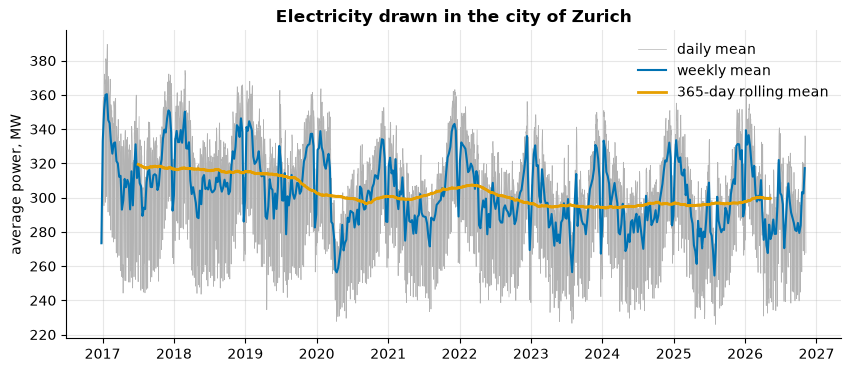

In [7]:
total = local["total_mwh"].rename("MW")
daily = total.resample("D").mean()
weekly = total.resample("W-MON", label="left", closed="left").mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily, lw=0.5, color="0.7", label="daily mean")
ax.plot(weekly.index, weekly, lw=1.5, label="weekly mean")
ax.plot(daily.rolling(365, center=True).mean(), lw=2, label="365-day rolling mean")
ax.set(title="Electricity drawn in the city of Zurich", ylabel="average power, MW")
ax.legend();

Three things are visible before any model: a strong yearly cycle (winter is higher), a slow
decline in the rolling mean, and a dip in spring 2020. Chapter 2 separates them.

## The national picture

The federal energy office publishes Switzerland's consumption by week since 2003. A second,
coarser series is a good check: is what we see in Zurich a Zurich effect, or a Swiss one?

weeks in common: 501 | correlation: 0.753


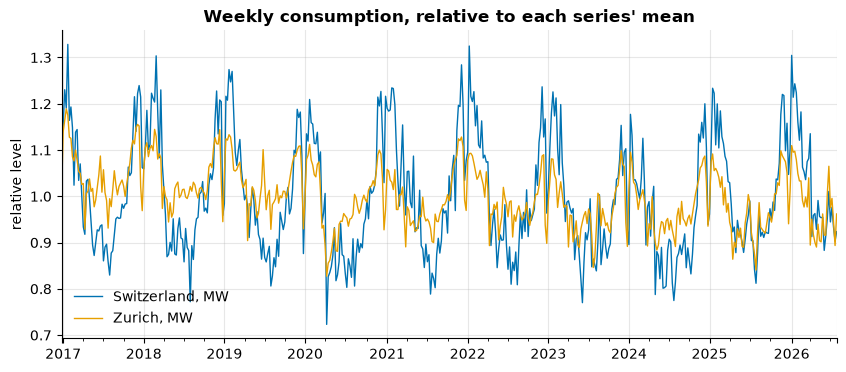

In [8]:
ch = io.load_sample("enstat_switzerland_weekly.csv", parse_dates=["week_start"]).set_index("week_start")
ch_mw = (ch["consumption_gwh"] * 1000 / (7 * 24)).rename("Switzerland, MW")
zh_week = total.tz_localize(None).resample("W-WED", label="left", closed="left").mean()
both = pd.concat([ch_mw, zh_week.rename("Zurich, MW")], axis=1, join="inner").dropna()

fig, ax = plt.subplots(figsize=(10, 4))
(both / both.mean()).plot(ax=ax, lw=1)
ax.set(title="Weekly consumption, relative to each series' mean", ylabel="relative level")
print("weeks in common:", len(both), "| correlation:", round(both.corr().iloc[0, 1], 3))

Zurich moves with the country, so lessons from this series are not purely local.

## What to remember

- Parse the time, make it the index, make it time-zone aware, and *check* for gaps.
- Store in UTC; build features in local time.
- Resample with the mean when the periods have different lengths.

## Exercises

1. Plot NE5 and NE7 separately as weekly means. Which level fell more since 2017?
2. Which local hour of the day has the highest mean load in January, and which in July?
3. Resample to months with `"MS"`. How many hours does February 2024 contain?

**Next:** [Chapter 2 · Trend and seasonality](02-trend-and-seasonality.ipynb)